# Tarea 2 · Parte 1. Corpus y extracción (OCR + ASR)

La pregunta de este trabajo es si se pueden convertir documentos escaneados y entrevistas en audio en un archivo de texto estructurado y buscable.

| | |
|---|---|
| **Fecha de extracción** | 22 de octubre de 2026 (descarga con `descargar.py`) |
| **Documentos** | 25 páginas de Wikimedia Commons. Son 8 impresos (Constituciones de 1823, 1828 y 1856, Gazeta de Lima de 1810, Gaceta del Gobierno de Lima independiente, *Tradiciones peruanas* de 1893, *Amauta* n.º 1 y una carta a máquina de 1914), 8 fotos de placas y letreros (Lima, Arequipa, Cusco, Trujillo) y 9 manuscritos (cartas de Carlos J. Bachmann a Ricardo Palma y de César Vallejo a José María Eguren de la Biblioteca Nacional del Perú, una carta de 1880 de Tacna y el Libro de Bautismos de Lampa). Hay 5 reservas (2 impresos, 2 fotos y 1 manuscrito, la carta de Miguel Grau de 1879) para reemplazar lo que salga ilegible |
| **Licencias de documentos** | Dominio público, CC0, CC BY-SA 3.0 y CC BY-SA 4.0 (una por archivo en `datos/fuentes.csv`) |
| **Audio** | 23 entrevistas y testimonios en español peruano de Wikimedia Commons (El Agustino, marchas en Lima, Junín, Áncash y otros), 61,8 min |
| **Licencias de audio** | CC BY-SA 4.0 y CC BY 4.0 |
| **OCR** | PaddleOCR 3.7.0 sobre PaddlePaddle 3.2.2, con detección PP-OCRv5 mobile, reconocimiento PP-OCRv6 medium y `lang="es"`. 6 documentos se procesaron en la CPU de la laptop y 24 en una GPU T4 de Google Colab, con la misma configuración |
| **ASR** | faster-whisper 1.2.1 con el modelo `small` (int8 en CPU), VAD Silero y diarización con WeSpeaker ResNet34 (pyannote.audio 4.0.7), usando las funciones de `voz.py` |

Los archivos originales quedan en `datos/raw/`, fuera de Git. En `datos/fuentes.csv` están la URL, la licencia, el autor y la forma de acceso de cada uno.

In [1]:
import hashlib, json, time, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import plotly.express as px
from IPython.display import Image as Img, display

import torch  # en Windows torch debe cargarse antes que paddle: si no, sus DLL chocan
import paddle, paddleocr, faster_whisper, pyannote.audio
import voz

warnings.filterwarnings("ignore")
pd.set_option("display.max_colwidth", 90)
RAIZ = Path(".").resolve()
RAW_DOC, RAW_AUDIO = RAIZ / "datos/raw/documentos", RAIZ / "datos/raw/audio"
OCR_DIR, ASR_DIR = RAW_DOC / "ocr", RAW_AUDIO / "salidas"
GRAF = RAIZ / "graficos"
for d in (OCR_DIR, ASR_DIR, GRAF):
    d.mkdir(parents=True, exist_ok=True)

print("PaddleOCR", paddleocr.__version__, "| PaddlePaddle", paddle.__version__,
      "| faster-whisper", faster_whisper.__version__, "| pyannote.audio", pyannote.audio.__version__)
fuentes = pd.read_csv("datos/fuentes.csv")
fuentes.groupby(["modalidad", "tipo", "licencia"]).size().rename("archivos").to_frame()

C:\Users\Nicolas Silva\Documents\GitHub\Python-Intermedio\tarea_2\.venv\Lib\site-packages\paddle\utils\cpp_extension\extension_utils.py:718: UserWarning: No ccache found. Please be aware that recompiling all source files may be required. You can download and install ccache from: https://github.com/ccache/ccache/blob/master/doc/INSTALL.md
  warnings.warn(warning_message)


C:\Users\Nicolas Silva\Documents\GitHub\Python-Intermedio\tarea_2\.venv\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


PaddleOCR 3.7.0 | PaddlePaddle 3.2.2 | faster-whisper 1.2.1 | pyannote.audio 4.0.7


archivos
modalidad tipo       licencia               
audio     entrevista CC BY 4.0             4
                     CC BY-SA 4.0         19
documento foto       CC BY-SA 4.0          9
                     CC0                   1
          impreso    CC0                   2
                     Public domain         8
          manuscrito CC BY-SA 3.0          1
                     CC0                   7
                     Public domain         2

## 1. Limpieza previa de duplicados y archivos que no abren

Antes de procesar, cada archivo se identifica por su hash SHA-256. Si dos archivos son idénticos se queda el primero. Las reservas (`doc_r01` a `doc_r05`) solo entran si algún documento del corpus se descarta.

In [2]:
def sha256(ruta):
    return hashlib.sha256(Path(ruta).read_bytes()).hexdigest()

docs = fuentes[fuentes.modalidad == "documento"].copy()
docs["archivo"] = [f"datos/raw/documentos/{i}.jpg" for i in docs.id]
audios = fuentes[fuentes.modalidad == "audio"].copy()
audios["archivo_audio"] = [str(next(RAW_AUDIO.glob(f"{i}.*")).relative_to(RAIZ)).replace("\\", "/") for i in audios.id]

docs["hash"] = docs.archivo.map(sha256)
audios["hash"] = audios.archivo_audio.map(sha256)
descartes = []
for tabla, col in ((docs, "archivo"), (audios, "archivo_audio")):
    dup = tabla[tabla.duplicated("hash")]
    descartes += [{"id": r.id, "motivo": "duplicado exacto (mismo hash)"} for r in dup.itertuples()]
docs, audios = docs.drop_duplicates("hash"), audios.drop_duplicates("hash")
print(f"Duplicados por hash: {len(descartes)}")
print(f"Documentos: {len(docs)} (incluye {docs.reserva.sum()} reservas) · Audios: {len(audios)}")

Duplicados por hash: 0
Documentos: 30 (incluye 5 reservas) · Audios: 23


## 2. OCR de los documentos con PaddleOCR

La configuración es la misma para todo el corpus.

- `lang="es"` usa PP-OCRv6 medium, el modelo de reconocimiento por defecto de PaddleOCR 3.7 para español.
- `text_detection_model_name="PP-OCRv5_mobile_det"` con `text_det_limit_side_len=1280` detecta las líneas con el modelo liviano. Con el detector por defecto la laptop de 7,7 GB de RAM se quedaba sin memoria. El reconocimiento, que es lo que decide la calidad en los manuscritos, se mantiene con el modelo grande.
- `use_doc_orientation_classify=False`, `use_textline_orientation=False` y `use_doc_unwarping=False` apagan tres modelos extra. Las 30 imágenes ya están derechas (se revisaron una por una), así que esos modelos solo sumaban memoria y tiempo.
- No hay otro preprocesamiento. Las imágenes entran tal como se bajaron, con 2000 px de ancho.

### Dónde y cómo se corrió

Los 5 primeros documentos y la reserva `doc_r05`, que se agregó después, se procesaron en la CPU de la laptop. Los 24 restantes se procesaron en una GPU T4 de Google Colab con `ocr_colab.ipynb`, con la misma versión y configuración, porque la laptop tardaba hasta 9 minutos por página. Colab baja las imágenes desde Commons y verifica con SHA-256 que sean idénticas a las locales. Como control, `doc_017` dio exactamente el mismo texto en CPU y en GPU.

El código de abajo es el que hace el OCR, y si se borra `datos/raw/documentos/ocr/` el notebook lo vuelve a correr completo. En la laptop, correr PaddleOCR dentro del notebook la dejaba sin memoria, así que los resultados se guardaron antes con la misma configuración. 6 documentos salieron de `precalcular.py`, que usa el mismo código en procesos separados y por tandas de 3 o 4 documentos, y 24 de `ocr_colab.ipynb`. Si el JSON de un documento ya existe, no se vuelve a correr el OCR.

Para cada documento quedan en `datos/raw/documentos/ocr/` el JSON crudo, con cajas, textos y confianzas, y la imagen con las cajas detectadas.

La columna `segundos_ocr` mezcla dos máquinas. En la CPU de la laptop, que estaba casi sin RAM libre, cada página tomó de 120 a 520 s, y en la GPU de Colab de 1 a 28 s. Son tiempos de cómputo y no dicen qué tan difícil es cada documento.

In [3]:
from paddleocr import PaddleOCR

CONFIG_OCR = dict(lang="es", use_doc_orientation_classify=False, use_doc_unwarping=False, use_textline_orientation=False,
                  text_detection_model_name="PP-OCRv5_mobile_det", text_det_limit_side_len=1280, text_det_limit_type="max")
MODELO_OCR = f"PaddleOCR {paddleocr.__version__} (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)"
ocr = None

def leer_documento(id_, archivo):
    global ocr
    crudo = OCR_DIR / f"{id_}.json"
    if not crudo.exists():
        if ocr is None:
            ocr = PaddleOCR(**CONFIG_OCR)
        t0 = time.perf_counter()
        r = ocr.predict(str(RAIZ / archivo))[0]
        r.save_to_img(str(OCR_DIR / f"{id_}_cajas.jpg"))
        res = {"rec_texts": list(r["rec_texts"]), "rec_scores": [float(s) for s in r["rec_scores"]],
               "rec_boxes": np.asarray(r["rec_boxes"]).tolist(), "segundos": time.perf_counter() - t0}
        crudo.write_text(json.dumps(res, ensure_ascii=False), encoding="utf-8")
    res = json.loads(crudo.read_text(encoding="utf-8"))
    return {"texto_ocr": "\n".join(res["rec_texts"]), "lineas": len(res["rec_texts"]),
            "confianza_media": float(np.mean(res["rec_scores"])) if res["rec_scores"] else 0.0,
            "segundos_ocr": res["segundos"]}

ocr_res = pd.DataFrame([leer_documento(r.id, r.archivo) for r in docs.itertuples()], index=docs.index)
docs = docs.join(ocr_res)
docs["caracteres"] = docs.texto_ocr.str.len()
docs[["id", "tipo", "lineas", "caracteres", "confianza_media", "segundos_ocr"]].round(2)

,id,tipo,lineas,caracteres,confianza_media,segundos_ocr
0,doc_001,impreso,28,919,0.96,173.69
1,doc_002,impreso,23,497,0.95,121.15
2,doc_003,impreso,23,708,0.89,125.06
3,doc_004,impreso,45,1314,0.72,396.56
4,doc_005,impreso,47,2522,0.95,517.02
5,doc_006,impreso,42,2632,0.99,27.87
6,doc_007,impreso,100,4177,0.98,3.76
7,doc_008,impreso,27,1443,0.95,1.18
8,doc_009,foto,13,201,0.95,1.65
9,doc_010,foto,12,166,0.92,0.85


### Documentos ilegibles

Se considera ilegible un documento en el que el OCR no encuentra texto útil: menos de 30 caracteres o confianza media menor a 0,5. Si un documento del corpus cae ahí, se descarta y entra la reserva del mismo tipo. Si no hay reserva de ese tipo, entra la primera reserva legible de otro tipo, para no bajar de 25 documentos. El umbral se fijó antes de ver los resultados y no se ajusta para salvar un documento.

In [4]:
docs["ilegible"] = (docs.caracteres < 30) | (docs.confianza_media < 0.5)
corpus = docs[~docs.reserva & ~docs.ilegible]
for tipo, meta in {"impreso": 8, "foto": 8, "manuscrito": 9}.items():
    faltan = meta - (corpus.tipo == tipo).sum()
    reservas = docs[docs.reserva & ~docs.ilegible & (docs.tipo == tipo)].head(max(faltan, 0))
    corpus = pd.concat([corpus, reservas])
faltan = 25 - len(corpus)
if faltan > 0:
    libres = docs[docs.reserva & ~docs.ilegible & ~docs.id.isin(corpus.id)]
    corpus = pd.concat([corpus, libres.head(faltan)])
descartes += [{"id": r.id, "motivo": f"ilegible para el OCR ({r.caracteres} caracteres, confianza {r.confianza_media:.2f})"}
              for r in docs[docs.ilegible & ~docs.reserva].itertuples()]
docs = corpus.sort_values("id")
print(docs.tipo.value_counts().to_string())

tipo
manuscrito    9
impreso       8
foto          8


Ejemplo de las cajas que detecta PaddleOCR en una foto de placa, que lee casi perfecto, y en `doc_017`, el manuscrito que se descartó por ilegible. En el manuscrito detecta las líneas, pero no reconoce la letra a mano.

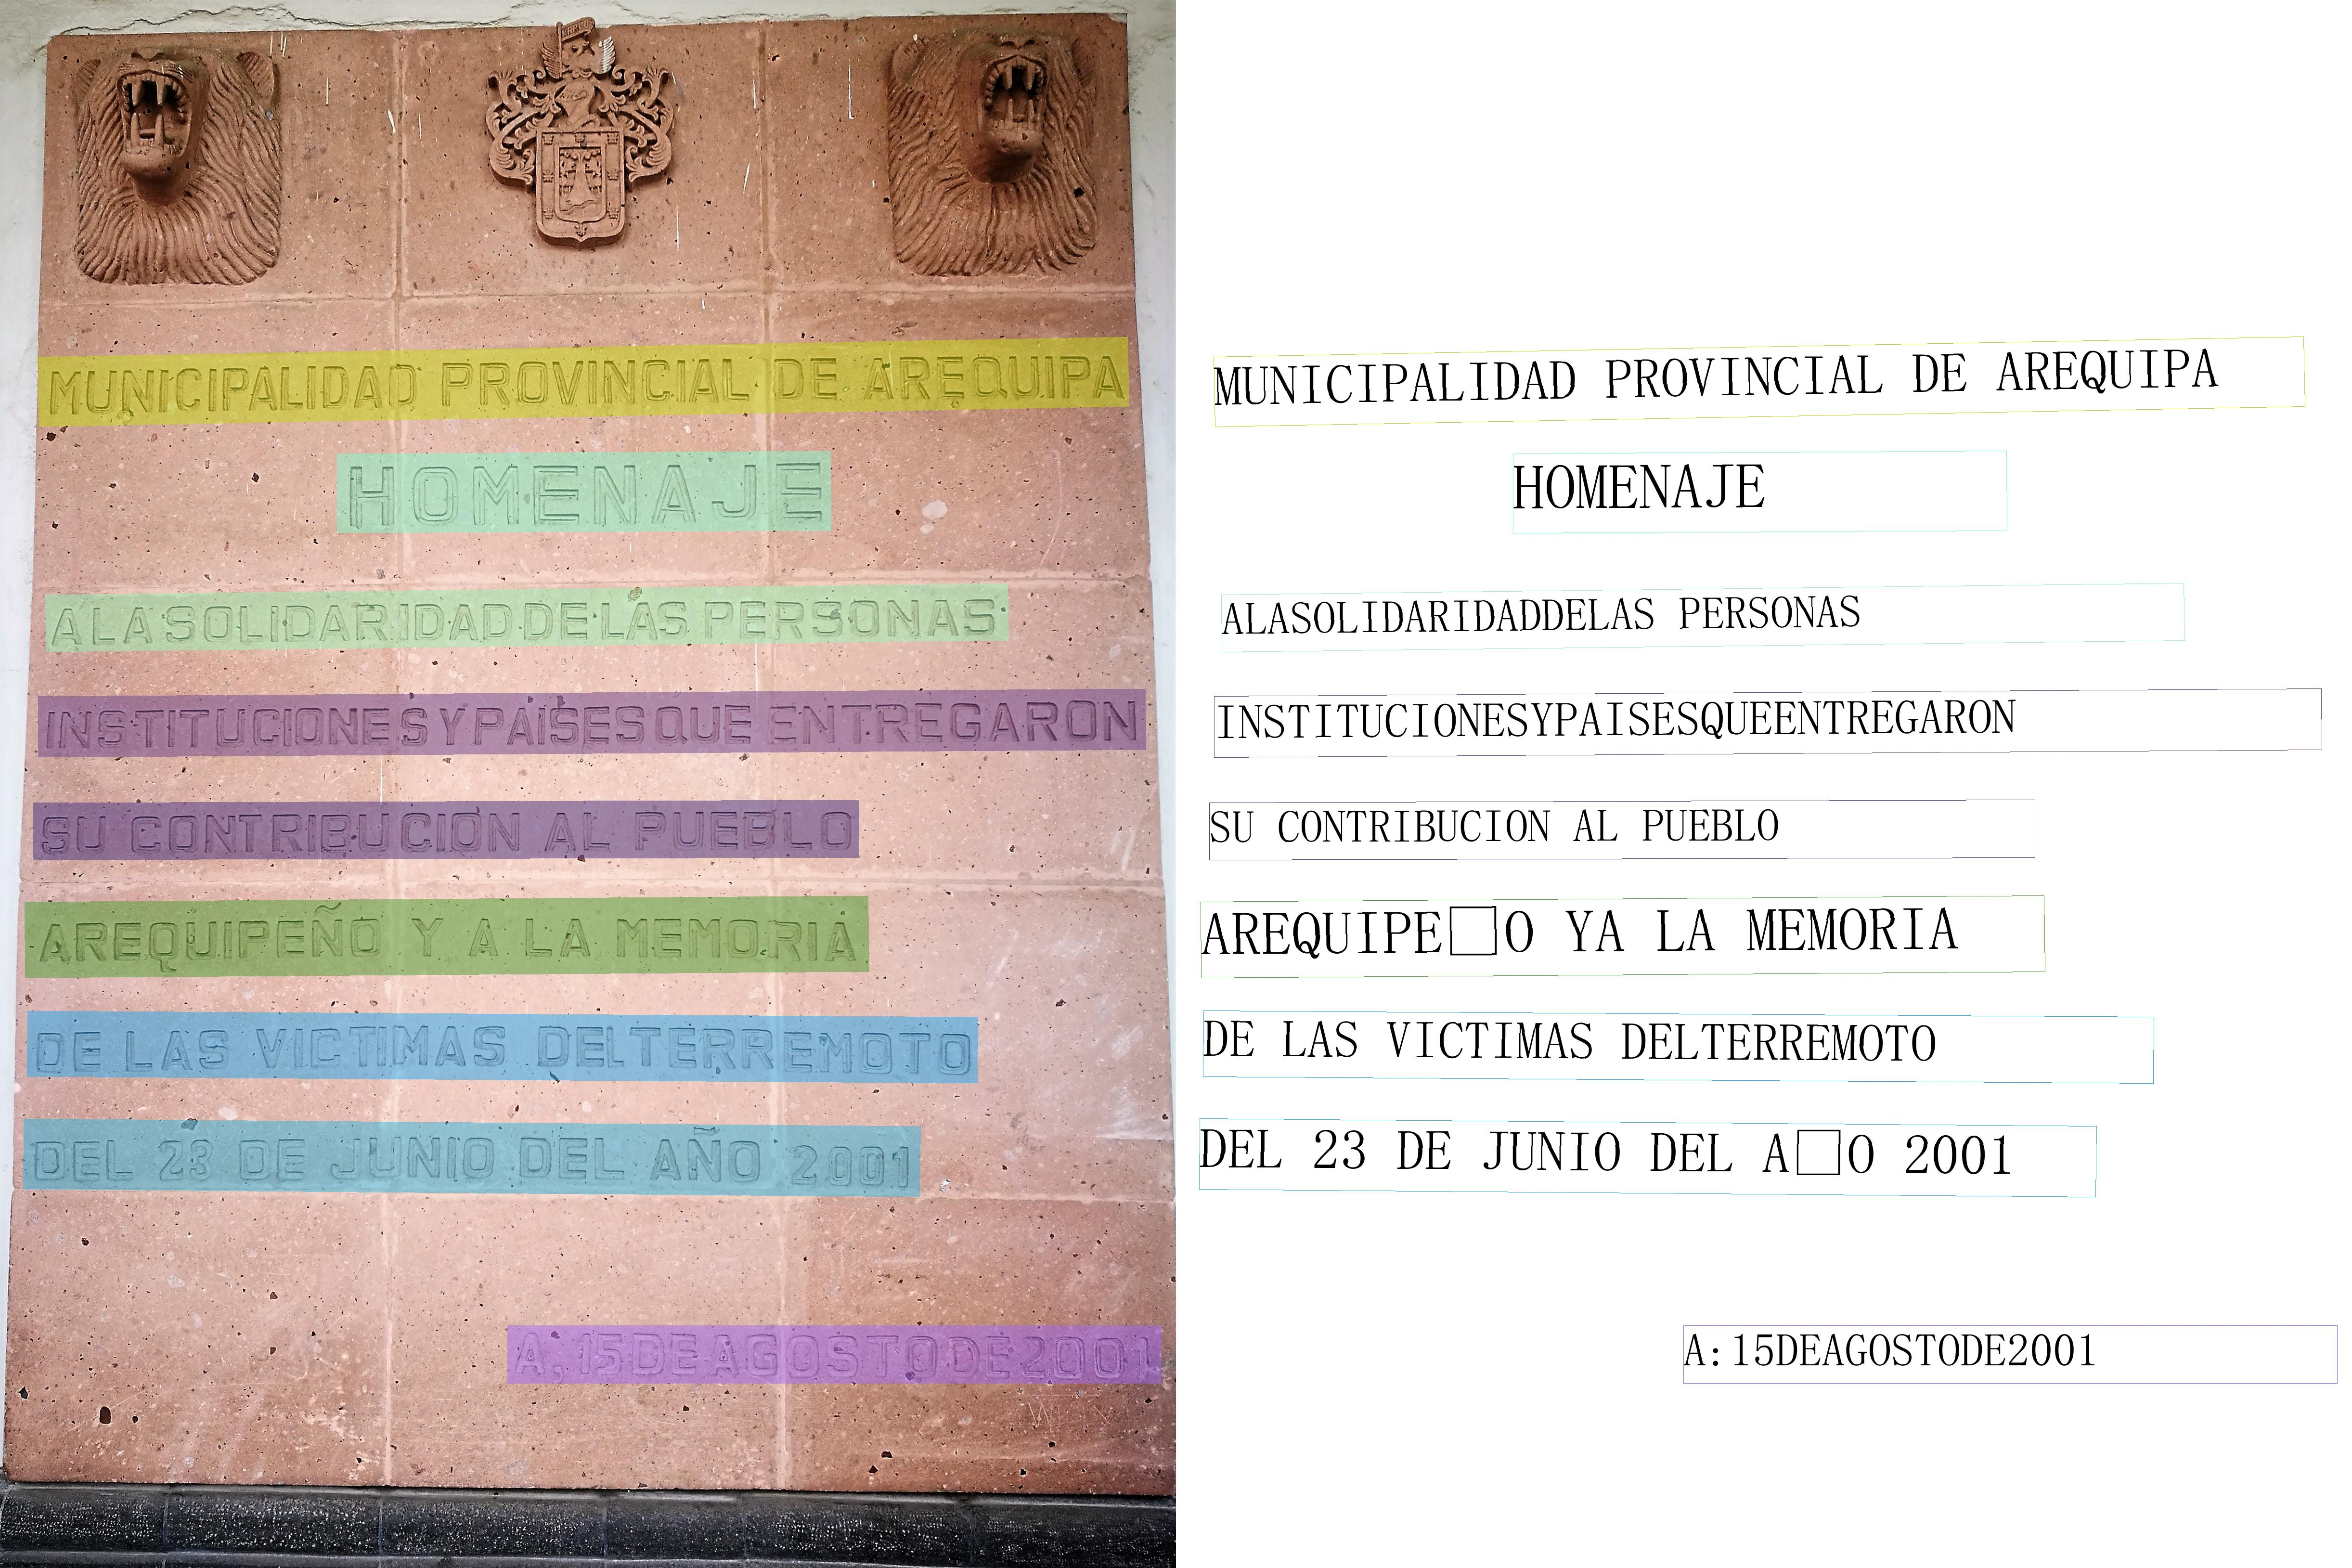

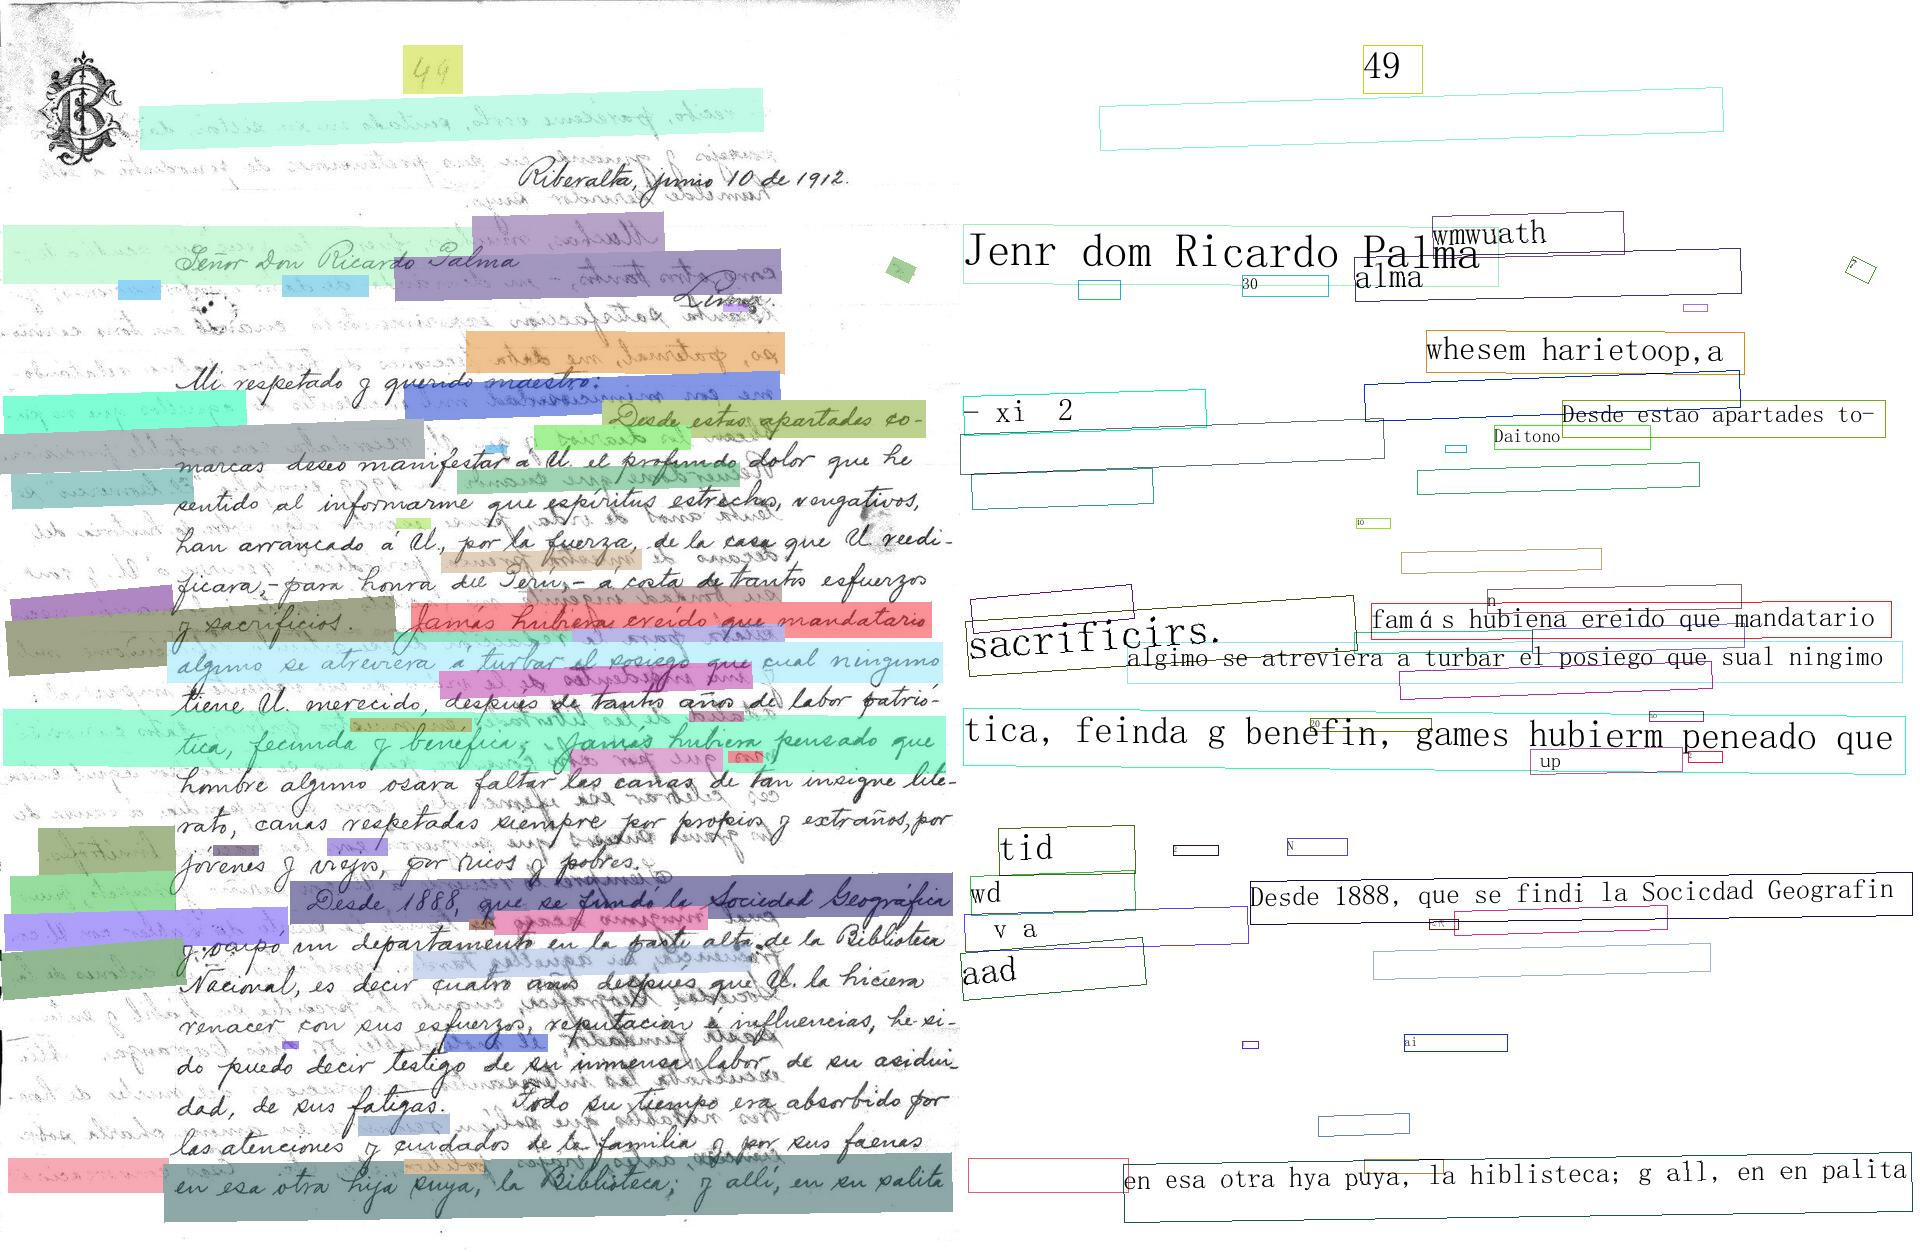

In [5]:
for i in ("doc_013", "doc_017"):
    display(Img(filename=str(OCR_DIR / f"{i}_cajas.jpg"), width=520))

## 3. Transcripción del audio (VAD + faster-whisper + diarización)

Los 23 clips pasan por los mismos pasos, con las funciones de `voz.py`.

1. `cargar_audio` convierte cualquier formato a mono de 16 kHz.
2. El **control de voz** usa el VAD Silero (`tramos_de_voz`). Si menos del 20 % del clip tiene voz, el clip se descarta como "sin voz".
3. La **transcripción** usa faster-whisper `small` en CPU (int8), con `language="es"`, `beam_size=5` y `vad_filter=True`. El filtro de voz evita que Whisper invente frases en los silencios.
4. La **diarización** (`diarizar`) saca una huella de voz de cada segmento con WeSpeaker ResNet34 y agrupa los segmentos por distancia coseno (umbral 0,7), sin decirle cuántas personas hay. En la primera pasada el umbral partía de más. Un clip de 58 segundos salía con 12 hablantes y otro con 6, la mayoría con 1 o 2 % del tiempo, que eran cambios de tono, risas o ruido de la calle. Por eso `diarizar` une cada grupo con menos del 5 % del tiempo hablado al grupo más parecido. Con esa regla los clips quedan con 1 a 4 hablantes, que es lo que se escucha.
5. Cada clip se **exporta** a CSV (segmentos), SRT (subtítulos) y TXT (turnos) en `datos/raw/audio/salidas/`.

Si el CSV de segmentos de un clip ya existe, no se vuelve a transcribir.

### Cómo se ejecutó

Igual que con el OCR, el código de abajo es el que transcribe y corre completo si se borra `datos/raw/audio/salidas/`. Los resultados se guardaron antes con `precalcular.py . asr`, con el mismo modelo, los mismos parámetros y el mismo `voz.py`, porque cargar faster-whisper y PaddleOCR en el mismo proceso agotaba la RAM de la laptop. La transcripción se cortó dos veces, una porque la laptop se suspendió y otra porque Windows cerró el proceso por falta de memoria, y se retomó desde el último clip guardado. La regla del 5 % se aplicó después a los 23 clips ya transcritos, volviendo a correr solo `diarizar` sobre los segmentos guardados.

In [6]:
MODELO_ASR = "faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker"
asr = None

def transcribir_clip(id_, archivo):
    global asr
    salida = ASR_DIR / f"{id_}.csv"
    audio = voz.cargar_audio(RAIZ / archivo)
    dur = len(audio) / voz.SR
    voz_seg = sum(b - a for a, b in voz.tramos_de_voz(audio))
    if not salida.exists():
        if asr is None:
            asr = voz.Transcriptor("faster-whisper-small", device="cpu")
        t0 = time.perf_counter()
        segs = asr.segmentos(audio, idioma="es")
        t_asr = time.perf_counter() - t0
        segs = voz.diarizar(audio, segs, device="cpu") if segs else []
        tabla = voz.a_tabla(segs)
        tabla["segundos_asr"] = t_asr
        tabla.to_csv(salida, index=False)
        (ASR_DIR / f"{id_}.srt").write_text(voz.a_srt(segs), encoding="utf-8")
        (ASR_DIR / f"{id_}.txt").write_text(voz.a_texto(segs), encoding="utf-8")
    tabla = pd.read_csv(salida).fillna({"texto": ""})
    return {"duracion_seg": round(dur, 1), "pct_voz": voz_seg / dur, "segmentos_csv": tabla,
            "segundos_asr": tabla.segundos_asr.iloc[0] if len(tabla) else 0.0}

clips = {r.id: transcribir_clip(r.id, r.archivo_audio) for r in audios.itertuples()}
audios["duracion_seg"] = audios.id.map(lambda i: clips[i]["duracion_seg"])
audios["pct_voz"] = audios.id.map(lambda i: clips[i]["pct_voz"])
audios["n_hablantes"] = audios.id.map(lambda i: clips[i]["segmentos_csv"].hablante.nunique())
audios["factor_tiempo_real"] = audios.id.map(lambda i: clips[i]["segundos_asr"]) / audios.duracion_seg
audios[["id", "duracion_seg", "pct_voz", "n_hablantes", "factor_tiempo_real"]].round(2)

,id,duracion_seg,pct_voz,n_hablantes,factor_tiempo_real
30,clip_001,136.3,0.77,2,0.35
31,clip_002,189.0,0.83,2,0.54
32,clip_003,250.6,0.96,2,0.77
33,clip_004,497.7,0.96,2,0.58
34,clip_005,526.9,0.97,1,0.65
35,clip_006,196.0,0.90,2,0.66
36,clip_007,96.1,0.85,2,0.44
37,clip_008,77.4,0.87,2,0.55
38,clip_009,163.9,0.86,2,0.50
39,clip_010,97.1,0.39,1,0.21


In [7]:
sin_voz = audios.pct_voz < 0.2
descartes += [{"id": r.id, "motivo": f"sin voz suficiente ({r.pct_voz:.0%} del clip)"} for r in audios[sin_voz].itertuples()]
audios = audios[~sin_voz]
multi = audios[audios.n_hablantes >= 2]
print(f"Clips con voz: {len(audios)} · {audios.duracion_seg.sum() / 60:.1f} min · "
      f"factor de tiempo real medio {audios.factor_tiempo_real.mean():.2f}")
print(f"Clips con 2 o más hablantes detectados: {len(multi)} ({', '.join(multi.id)})")

Clips con voz: 22 · 60.2 min · factor de tiempo real medio 0.54
Clips con 2 o más hablantes detectados: 14 (clip_001, clip_002, clip_003, clip_004, clip_006, clip_007, clip_008, clip_009, clip_012, clip_014, clip_015, clip_016, clip_018, clip_019)


Un ejemplo de la salida por turnos, con marcas de hablante, de una entrevista en la calle con dos voces.

In [8]:
ejemplo = multi.sort_values("duracion_seg").id.iloc[0]
seudonimos = json.loads(Path("modelos/seudonimos.json").read_text(encoding="utf-8")).get(ejemplo, {})
print(voz.seudonimizar((ASR_DIR / f"{ejemplo}.txt").read_text(encoding="utf-8"), seudonimos)[:1200])

[00:00:00] H1: Hola, buenas tardes, somos [PERSONA_1], en el censo se dan mayores al marco y en el momento si pueden participar en una entrevista. El caso hace que esta será grabada.

[00:00:09] H2: Ya está bien, ¿qué facultad sos?

[00:00:11] H1: Somos de las facultades sociales.

[00:00:13] H3: ¿Sincesas sociales?

[00:00:14] H1: Sin fotografías, para ser exacto.

[00:00:15] H3: ¿Ferafía?

[00:00:16] H1: Sí. La primera pregunta es ¿qué es el terreno para el terreno?

[00:00:19] H3: El terreno es diversidad.

[00:00:23] H1: ¿Cuáles son las características positivas del terreno?

[00:00:28] H2: Es que es emprendedor, trabajador.

[00:00:31] H1: Las principales características positivas.

[00:00:35] H2: Ah, es que no somos a [PERSONA_1].

[00:00:37] H1: La desorganización.

[00:00:38] H2: La desorganización, claro.

[00:00:41] H3: Apagados un poco a la regla.

[00:00:43] H1: Sí. Y el Perú, ¿cómo le escribí en una sola palabra?

[00:00:47] H2: Bonito. ¿Cómo dicen? Bonito. Maravilloso.

[

## 4. Seudonimización

Todos los textos se revisaron a mano con este criterio.

- Las **personas privadas** se reemplazan por `[PERSONA_n]`. Son los entrevistados, las personas que ellos nombran, los bautizados y padrinos de los libros parroquiales y los familiares de las cartas.
- Las **figuras públicas e históricas** que aparecen por su rol público se mantienen, por ejemplo Ricardo Palma, César Vallejo, presidentes y autoridades que firman normas o placas. No son datos personales en el sentido de la ley y quitarlas haría ininteligible el documento.
- Los **DNI, teléfonos y correos** se buscan con expresiones regulares y se reemplazan por `[DNI]`, `[TELEFONO]` y `[CORREO]`.

Los nombres a reemplazar salen de leer cada texto y se cargan en `REEMPLAZOS`. La función `voz.seudonimizar` compara de forma aproximada, así que también encuentra los nombres que el OCR o el ASR escribieron mal.

In [9]:
import re
REEMPLAZOS = json.loads(Path("modelos/seudonimos.json").read_text(encoding="utf-8"))
PATRONES = {"[DNI]": r"\b\d{8}\b", "[TELEFONO]": r"\b9\d{2}[ -]?\d{3}[ -]?\d{3}\b", "[CORREO]": r"\b[\w.+-]+@[\w-]+\.[\w.]+\b"}

def seudonimizar(texto, id_):
    conteo = 0
    for patron_tag, patron in PATRONES.items():
        texto, n = re.subn(patron, patron_tag, texto)
        conteo += n
    tabla = REEMPLAZOS.get(id_, {})
    if tabla:
        nuevo = voz.seudonimizar(texto, tabla)
        conteo += sum(nuevo.count(s) - texto.count(s) for s in set(tabla.values()))
        texto = nuevo
    return texto, conteo

docs[["texto_ocr", "entidades"]] = [seudonimizar(t, i) for t, i in zip(docs.texto_ocr, docs.id)]

def texto_con_hablantes(id_):
    seg = clips[id_]["segmentos_csv"]
    turnos = []
    for s in seg.itertuples():
        if turnos and turnos[-1][0] == s.hablante:
            turnos[-1][1].append(str(s.texto))
        else:
            turnos.append([s.hablante, [str(s.texto)]])
    return " ".join(f"[HABLANTE_{h[1:]}] {' '.join(x)}" for h, x in turnos)

audios[["texto_asr", "entidades"]] = [seudonimizar(texto_con_hablantes(i), i) for i in audios.id]
print(f"Entidades reemplazadas: {docs.entidades.sum()} en documentos y {audios.entidades.sum()} en audios")
pd.concat([docs[["id", "entidades"]], audios[["id", "entidades"]]]).query("entidades > 0").set_index("id").T

Entidades reemplazadas: 7 en documentos y 34 en audios


id,doc_022,doc_024,clip_001,clip_002,clip_003,clip_004,clip_005,clip_006,clip_007,clip_008,clip_009,clip_012,clip_014,clip_018,clip_019
entidades,3,4,2,9,2,3,1,4,2,1,3,1,2,2,2


## 5. Reporte de descartes

In [10]:
reporte = pd.DataFrame(descartes, columns=["id", "motivo"])
print(f"Archivos descartados: {len(reporte)}")
reporte if len(reporte) else print("Ningún archivo del corpus se descartó: no hubo duplicados, documentos ilegibles ni audios sin voz.")

Archivos descartados: 2


,id,motivo
0,doc_017,"ilegible para el OCR (432 caracteres, confianza 0.40)"
1,clip_011,sin voz suficiente (11% del clip)


## 6. Análisis exploratorio

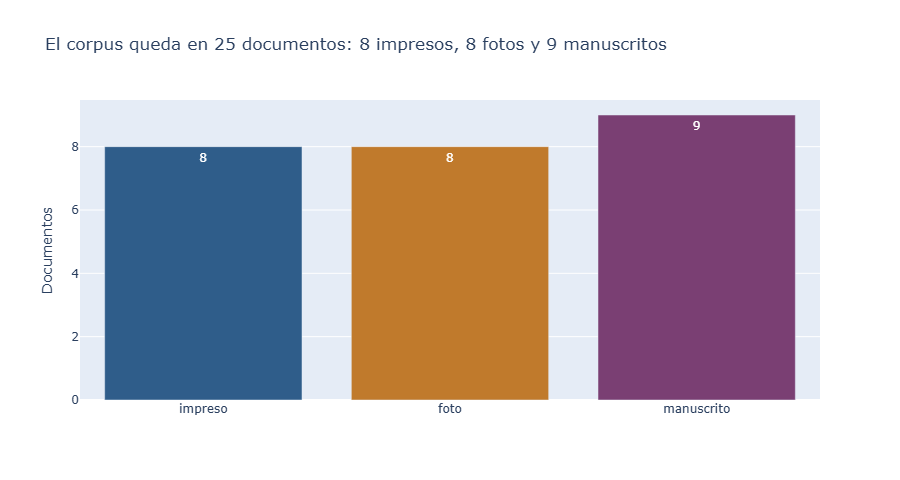

In [11]:
def guardar(fig, nombre):
    fig.write_image(GRAF / f"{nombre}.png", width=900, height=480, scale=1)
    fig.show()
    display(Img(filename=str(GRAF / f"{nombre}.png")))

COLORES = {"impreso": "#2f5d8a", "foto": "#c07a2c", "manuscrito": "#7a3f73"}
conteo = docs.groupby("tipo", as_index=False).agg(documentos=("id", "size"), caracteres=("caracteres", "median"))
n = conteo.set_index("tipo").documentos
TITULO_1 = (f"El corpus queda en {len(docs)} documentos: {n['impreso']} impresos, {n['foto']} fotos y "
            f"{n['manuscrito']} manuscritos")
fig = px.bar(conteo, x="tipo", y="documentos", color="tipo", color_discrete_map=COLORES, text="documentos",
             category_orders={"tipo": ["impreso", "foto", "manuscrito"]},
             title=TITULO_1)
fig.update_layout(showlegend=False, xaxis_title="", yaxis_title="Documentos")
guardar(fig, "documentos_por_tipo")

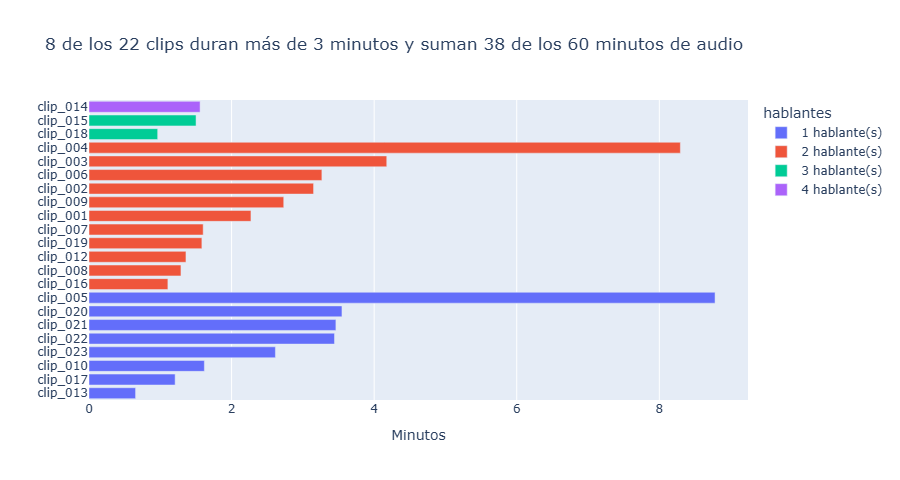

In [12]:
dur = audios.assign(minutos=audios.duracion_seg / 60, hablantes=audios.n_hablantes.astype(str) + " hablante(s)")
largos = dur[dur.minutos > 3]
TITULO_2 = (f"{len(largos)} de los {len(dur)} clips duran más de 3 minutos y suman {largos.minutos.sum():.0f} "
            f"de los {dur.minutos.sum():.0f} minutos de audio")
fig = px.bar(dur.sort_values("minutos"), x="minutos", y="id", color="hablantes", orientation="h",
             hover_data=["licencia"], title=TITULO_2,
             category_orders={"hablantes": sorted(dur.hablantes.unique())})
fig.update_layout(xaxis_title="Minutos", yaxis_title="", height=620)
fig.update_yaxes(tickmode="linear")
guardar(fig, "duracion_por_clip")

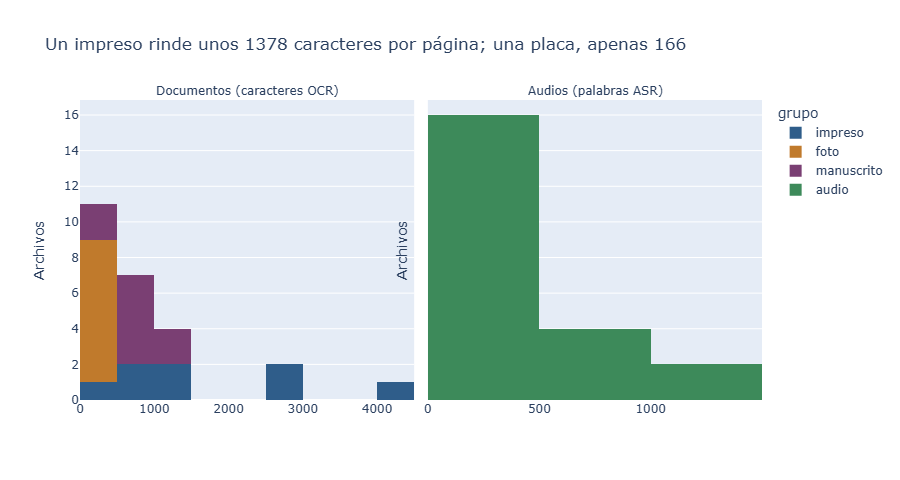

In [13]:
largo = pd.concat([
    pd.DataFrame({"modalidad": "Documentos (caracteres OCR)", "longitud": docs.caracteres, "grupo": docs.tipo}),
    pd.DataFrame({"modalidad": "Audios (palabras ASR)", "longitud": audios.texto_asr.str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len(), "grupo": "audio"}),
])
med = docs.groupby("tipo").caracteres.median()
TITULO_3 = (f"Un impreso rinde unos {med['impreso']:.0f} caracteres por página; una placa, apenas "
            f"{med['foto']:.0f}")
fig = px.histogram(largo, x="longitud", color="grupo", facet_col="modalidad", nbins=15,
                   color_discrete_map=COLORES | {"audio": "#3d8a5a"}, title=TITULO_3)
fig.update_xaxes(matches=None, title="")
fig.update_yaxes(title="Archivos")
fig.for_each_annotation(lambda a: a.update(text=a.text.split("=")[-1]))
guardar(fig, "longitud_textos")

## 7. Validación de extremos

Los 3 documentos con el OCR más largo y más corto, y los 3 clips más largos y más cortos, para comprobar que los histogramas reflejan lo que de verdad hay en cada archivo.

In [14]:
cols = ["id", "tipo", "caracteres", "confianza_media"]
extremos_doc = pd.concat([docs.nlargest(3, "caracteres").assign(extremo="más largo"),
                          docs.nsmallest(3, "caracteres").assign(extremo="más corto")])
extremos_doc.assign(inicio=extremos_doc.texto_ocr.str[:80].str.replace("\n", " "))[["extremo"] + cols + ["inicio"]].round(2)

,extremo,id,tipo,caracteres,confianza_media,inicio
6,más largo,doc_007,impreso,4177,0.98,A M AU T A 1 VIII LIMA 1926 DOOTRINA ARTE LITERATURA POLEMICA PRESENTACIONDE“AMA
5,más largo,doc_006,impreso,2632,0.99,JUICIOS LITERARIOS xv Luego me llevó á conocer todos los departamentos del edifi
4,más largo,doc_005,impreso,2522,0.95,"3 esta coluna se colocarà el busto del benemèrito jeneral Antonio José de Sncre,"
13,más corto,doc_014,foto,35,0.99,CAPILLA DE NUESTRA SEÑORA DE LORETO
22,más corto,doc_023,manuscrito,45,0.91,2 LIBRODE BAUTISMOS Que comienza el año ytela
15,más corto,doc_016,foto,51,0.96,"CASAAMOROS PINTURAMURALS.XVIP"" TRU ILLO JULIO E201G"


In [15]:
audios["palabras"] = audios.texto_asr.str.replace(r"\[HABLANTE_\d+\]", "", regex=True).str.split().str.len()
extremos_aud = pd.concat([audios.nlargest(3, "duracion_seg").assign(extremo="más largo"),
                          audios.nsmallest(3, "duracion_seg").assign(extremo="más corto")])
extremos_aud["palabras_por_min"] = extremos_aud.palabras / (extremos_aud.duracion_seg / 60)
extremos_aud.assign(inicio=extremos_aud.texto_asr.str[:80])[["extremo", "id", "duracion_seg", "palabras", "palabras_por_min", "n_hablantes", "inicio"]].round(1)

,extremo,id,duracion_seg,palabras,palabras_por_min,n_hablantes,inicio
34,más largo,clip_005,526.9,1264,143.9,1,[HABLANTE_1] mi nombre es [PERSONA_1]. ¿De dónde vienes y de qué? ¿Cuál es tu co
33,más largo,clip_004,497.7,1001,120.7,2,"[HABLANTE_1] ¿Qué esperamos? [HABLANTE_2] Bien, estamos en Plata San Martín. Ant"
32,más largo,clip_003,250.6,642,153.7,2,"[HABLANTE_1] Bueno, hola, estamos en los San Martín, entre Fristas Patreas, 28 d"
42,más corto,clip_013,39.2,74,113.3,1,"[HABLANTE_1] Buenos días, joven. Claro que sí, la fiesta de Santo Patrón de Chuy"
47,más corto,clip_018,57.8,125,129.8,3,"[HABLANTE_1] Hola, buenas tardes, somos [PERSONA_1], en el censo se dan mayores"
45,más corto,clip_016,66.4,128,115.7,2,[HABLANTE_1] Hola a todos estudiantes de la Universidad Nacional Mayor de San Ma


**Lectura de los extremos**

- Los tres **documentos más largos** son impresos de página completa y letra chica (*Amauta* a dos columnas, *Tradiciones peruanas* y la *Gaceta del Gobierno de Lima independiente*), con confianza de 0,95 o más. Son las barras azules de la derecha del histograma, porque ningún otro tipo pasa de 2 000 caracteres.
- Los **documentos más cortos** son dos letreros fotografiados (35 y 51 caracteres) y la portada del Libro de Bautismos de 1655, que solo tiene el título. No son fallas del OCR. En los tres la confianza es de 0,91 o más y el texto leído es el que se ve en la imagen. Coinciden con la primera barra del histograma, donde casi todo son fotos.
- Los **clips más largos** son el testimonio de 8,8 min (1 264 palabras) y la entrevista de 8,3 min (1 001 palabras), que forman la cola derecha del histograma de palabras.
- Los **clips más cortos** duran de 39 a 66 segundos y tienen de 74 a 128 palabras.
- En los seis clips extremos el ritmo va de 113 a 154 palabras por minuto, un rango normal para habla espontánea. El largo de cada transcripción sigue a la duración del audio y no a cortes del ASR.

## 8. Exportación

In [16]:
docs["fuente"] = docs.licencia.radd("Wikimedia Commons (") + ") " + docs.fuente_url
documentos = docs.assign(modelo_ocr=MODELO_OCR, texto_referencia="")[
    ["id", "archivo", "tipo", "fuente", "texto_ocr", "modelo_ocr", "texto_referencia"]]
transcripciones = audios.assign(idioma="es (español peruano, según la ficha de cada audio)", modelo_asr=MODELO_ASR,
                                texto_referencia="")[
    ["id", "archivo_audio", "duracion_seg", "idioma", "texto_asr", "modelo_asr", "n_hablantes", "texto_referencia"]]
publicados = set(documentos.id) | set(transcripciones.id)
# fuentes.csv conserva también las reservas; el título del archivo en Commons no se publica porque
# en las entrevistas incluye el nombre de la persona (queda en la URL, necesaria para verificar la fuente)
fuentes_pub = fuentes.drop(columns=["titulo"], errors="ignore").assign(en_corpus=fuentes.id.isin(publicados))

documentos.to_csv("datos/documentos.csv", index=False)
transcripciones.to_csv("datos/transcripciones.csv", index=False)
fuentes_pub.to_csv("datos/fuentes.csv", index=False)
for nombre, df in {"documentos": documentos, "transcripciones": transcripciones, "fuentes": fuentes_pub}.items():
    print(nombre, df.shape)
print(f"Audio total: {transcripciones.duracion_seg.sum() / 60:.1f} min en {len(transcripciones)} clips")

documentos (25, 7)
transcripciones (22, 8)
fuentes (53, 13)
Audio total: 60.2 min en 22 clips


In [17]:
documentos.head()

,id,archivo,tipo,fuente,texto_ocr,modelo_ocr,texto_referencia
0,doc_001,datos/raw/documentos/doc_001.jpg,impreso,Wikimedia Commons (Public domain) https://commons.wikimedia.org/wiki/File:Constitucion...,"CAPITULOIII.\n5\nRELIJION.\nAat. 8. La Relijion de Ja República, es\nla Católica, Apos...","PaddleOCR 3.7.0 (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)",
1,doc_002,datos/raw/documentos/doc_002.jpg,impreso,Wikimedia Commons (Public domain) https://commons.wikimedia.org/wiki/File:Constituci%C...,"EL CIUDADANO JOSE DE LA-MAR,\nPRESIDENTE DE LA REPUBLICA.\nPor cuanto el Congreso ha d...","PaddleOCR 3.7.0 (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)",
2,doc_003,datos/raw/documentos/doc_003.jpg,impreso,Wikimedia Commons (Public domain) https://commons.wikimedia.org/wiki/File:Constituci%C...,"EL LIBERTADOR BANON GASTILLA,\nGRAN MARISCAL DELOS EJERCITOS,\nCONDECORADO-CON LAS MED...","PaddleOCR 3.7.0 (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)",
3,doc_004,datos/raw/documentos/doc_004.jpg,impreso,Wikimedia Commons (Public domain) https://commons.wikimedia.org/wiki/File:Gazeta_del_g...,14\n38\n↑le\n03\nGAZETA DEL GOBIERNO\neaga)\nA\nst\n\nww\nDE LIMA.\nki\not \n\nPERN\n\...,"PaddleOCR 3.7.0 (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)",
4,doc_005,datos/raw/documentos/doc_005.jpg,impreso,Wikimedia Commons (Public domain) https://commons.wikimedia.org/wiki/File:Gaceta_del_G...,"3\nesta coluna se colocarà el busto del benemèrito jeneral Antonio\nJosé de Sncre, y e...","PaddleOCR 3.7.0 (lang=es, det PP-OCRv5 mobile, rec PP-OCRv6 medium, orientación off)",


In [18]:
transcripciones.head()

,id,archivo_audio,duracion_seg,idioma,texto_asr,modelo_asr,n_hablantes,texto_referencia
30,clip_001,datos/raw/audio/clip_001.ogg,136.3,"es (español peruano, según la ficha de cada audio)","[HABLANTE_1] Buenos días, aquí son las 10 y 28 y estoy con una señora que va a darme s...","faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,
31,clip_002,datos/raw/audio/clip_002.ogg,189.0,"es (español peruano, según la ficha de cada audio)",[HABLANTE_1] Buenos días profesor y compañeros. Hoy estoy cerca de aquí por mi casa y ...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,
32,clip_003,datos/raw/audio/clip_003.ogg,250.6,"es (español peruano, según la ficha de cada audio)","[HABLANTE_1] Bueno, hola, estamos en los San Martín, entre Fristas Patreas, 28 de juli...","faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,
33,clip_004,datos/raw/audio/clip_004.ogg,497.7,"es (español peruano, según la ficha de cada audio)","[HABLANTE_1] ¿Qué esperamos? [HABLANTE_2] Bien, estamos en Plata San Martín. Antes que...","faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker",2,
34,clip_005,datos/raw/audio/clip_005.ogg,526.9,"es (español peruano, según la ficha de cada audio)",[HABLANTE_1] mi nombre es [PERSONA_1]. ¿De dónde vienes y de qué? ¿Cuál es tu comunida...,"faster-whisper small (int8, CPU, VAD Silero on, beam 5) + diarización WeSpeaker",1,
